#DEEP Week 3 Practical: solutions and review session

This is the Week 3 practical with solutions, plus extra **Review** sections (marked 🔎) that go with the review session slides. They answer questions that came up in the practical:

1. Why does stacking linear layers without an activation collapse to a single linear layer? (end of exercise 3)
2. Why does each ReLU neuron add one straight line segment? (after exercise 2)
3. Why did some exercise 2 runs fit the sinusoid badly, and why does standardising the inputs help? (after exercise 2)
4. Why does a network with 1,000 hidden neurons need a smaller learning rate, and how do you compare widths fairly? (after exercise 2)
5. Why didn't the size of the network matter in exercise 1? (after exercise 1)

Everything in the review sections is a real experiment you can rerun and change. Each review section is self-contained (it creates its own data), so you can run them in any order after the first code cell.

##1. MLP for breast cancer data

I've given you the code to load the dataset and train a single hidden layer MLP. This is a simple extension of the logistic regression implementation in PyTorch that you saw last week but now we have more than just the one linear layer. Read and understand the code, click through and then try the tasks at the end.

In [ ]:
import numpy as np
import torch
import matplotlib
from numpy import pi
import torch.nn as nn

Load the dataset and convert to PyTorch tensors

In [ ]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data

training_size = 400

data = np.genfromtxt('breast-cancer-wisconsin.data',delimiter=',',missing_values='?')
data = data[~np.isnan(data).any(axis=1)]

# Convert labels to binary 0/1 classes as expected by PyTorch
y_01 = np.array([0 if x==2 else 1 for x in data[:,-1]])

X = data[:,1:-1] # ignore first column and omit class variable at the end



In [ ]:
# Split train/test and convert to PyTorch tensors
X_train_tensor = torch.from_numpy(np.float32(X[:training_size]))
Y_train_tensor = torch.from_numpy(np.float32(y_01[:training_size])).unsqueeze(1)
X_test_tensor = torch.from_numpy(np.float32(X[training_size:]))
Y_test_tensor = torch.from_numpy(np.float32(y_01[training_size:])).unsqueeze(1)

Let's make sure that we understand the structure of our data. Let's start by printing the shapes of the training data inputs and labels (always a good idea!)

In [ ]:
print(X_train_tensor.shape)
print(Y_train_tensor.shape)

So, our training data comprises 400 samples. Each sample comprises a 9 dimensional input and a binary label. In other words `X_train_tensor[i,:]` is the 9D input for training sample `i` and `Y_train_tensor[i]` contains either a 0 or 1 to indicate which class it belongs to.

###Define a single hidden layer MLP

We will now define a simple MLP that we will use to solve this problem. This MLP will allow us to specify the input size and the number of neurons in the hidden layer when we instantiate it. It will contain one hidden layer followed by ReLU activation. Since this is a binary classification problem, the output layer will map the output of the hidden layer to a single output which will represent the probability of one of the classes. Since we need the output to represent a probability, we will use sigmoid to map the unconstrained value to a value between 0 and 1.

In [ ]:
class MLP(nn.Module):
    def __init__(self, inputSize, hiddenSize):
        # Call superclass constructor
        super(MLP, self).__init__()
        # Initialise components of model:
        # 1. First linear layer (hidden layer)
        self.linear1 = nn.Linear(inputSize, hiddenSize)
        # 2. ReLU layer
        self.relu = nn.ReLU()
        # 3. Second linear layer (output layer)
        self.linear2 = nn.Linear(hiddenSize, 1)
        # 4. Sigmoid layer
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Forward pass through the model:
        # x has shape batch x inputSize
        # HIDDEN LAYER
        # 1. Apply linear layer to input
        y = self.linear1(x)
        # y has shape batch x 16
        # 2. Apply ReLU to output of linear layer
        y = self.relu(y)
        # OUTPUT LAYER
        # 3. Apply linear layer to output of hidden layer
        y = self.linear2(y)
        # y has shape batch x 1
        # 4. Apply sigmoid to output of linear layer
        y = self.sigmoid(y)
        return y

Let's just remind ourselves how this model is actually used. First, we want to instantiate it. At this point, the learnable weights and biases are initialised with random values. If you've run some learning and want to start again from scratch, you need to rerun this line, otherwise the weights will be preserved from your previous training.

In [ ]:
# Instantiate MLP with 9 channel input and 16 neuron hidden layer
model = MLP(9,16)

Now let's just check that we understand the shapes of inputs and outputs to the model. Let's create some random input and put it through the model.

In [ ]:
x = torch.randn(100,9)
y = model(x)
print(y.shape)
print(torch.min(y))
print(torch.max(y))

The first dimension of `x` is the batch size. We are allowed to pass many inputs through a model in parallel and this first dimension (100 in this case) represents this. The second dimension is the size of the input - in this case we have 9D input. The output has shape $100\times 1$, i.e. a scalar probability for each of the 100 inputs. We can see that the values in `y` lie between 0 and 1.

###Training the model

We're now ready to try training the model. We need to define a loss function, set up the optimiser and then run the training loop. We will use binary cross entropy loss and straightforward gradient descent. For each iteration (="epoch" because we process the entire training set in each operation - this will be different when we come to using minibatches later) of the training loop, we simply put the inputs through our model, get probabilities out (`y_predict`) and put these into the loss function to compare against the binary labels. We then perform backprop and take a gradient descent step.

In [ ]:
epochs = 5000

# Instantiate loss function (binary cross entropy loss - sigmoid applied inside model)
criterion = torch.nn.BCELoss()
# Setup optimiser
optim = torch.optim.SGD(model.parameters(), lr=0.1)

# Main training loop
for epoch in range(epochs):
    # Pass training data through model
    y_predict = model(X_train_tensor)
    # Compute BCE loss
    loss = criterion(y_predict,Y_train_tensor)
    # Backward pass and gradient step
    optim.zero_grad()
    loss.backward()
    optim.step()
    if not epoch % 200:
        # Print out the loss every 10 iterations
        print('epoch {}, loss {}'.format(epoch, loss.item()))

###Evaluating our model

Hopefully, the loss gradually reduced while your model trained. This is promising but the loss value is a bit hard to interpret. Let's now calculate the percentage correct classification on both the training and test sets. To convert the estimated probabilities into hard classifications, we simply threshold against 0.5. We can then compare the predictions against the actual labels.

In [ ]:
# Pass training set set through model
y_predict = model(X_train_tensor)
# Threshold probabilities to binary classes
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_train_tensor).float().sum()
print("Percent training set correctly classified: {:.2f}%".format(100*correct/training_size))

# Pass test set through model
y_predict = model(X_test_tensor)
# Threshold probabilities to binary classes
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_test_tensor).float().sum()
print("Percent test set correctly classified: {:.2f}%".format(100*correct/X_test_tensor.shape[0]))

Depending on your random seed, performance should be in the high 90s and performance on the test set will be slightly different, possibly in either direction.

###A note of caution: bias

When we split the dataset into a training and test set, we simply took the first 400 samples as training data and the remainder as test data. It is always a good idea to check whether your dataset is biased and, if so, whether the bias is the same in both the training and test sets.

In [ ]:
print("Percent of train set with class 1: {:.2f}".format(Y_train_tensor.sum()/Y_train_tensor.shape[0]))
print("Percent of test set with class 1: {:.2f}".format(Y_test_tensor.sum()/Y_test_tensor.shape[0]))

As you can see, our dataset is slightly biased (more class 0 than class 1). However, the bias is worse in the test set than training set. This might be bad.

If your goal is to maximise performance for any unseen test set, then ideally the training set would be unbiased. There are various strategies you could use for this. One option is to weight the loss by inverse class frequency. Another is to use a weighted sampling such that samples from the underrepresented class get used in training more often. But we won't worry about this for now.

If your goal is to maximise performance on the given test set then we would like the bias to be the same in both training and test set. One strategy to achieve this is to randomly shuffle the data before splitting into training and test.

###Tasks

1. Apply the same random shuffle to `X` and `y_01` before splitting into train and test. Verify that this leads to the same (or very similar) bias in each dataset. Retrain your model. Does this change performance at all?
2. Experiment with a smaller MLP - i.e. reduce the number of hidden neurons. How small can you make it while still achieving good performance? If you make it really small, eventually it can't extract any useful information from the features in which case it will only learn the bias (i.e. it will just always predict the more common class and will be right with chance performance). Can you see this happening? What performance do you get?
3. Experiment with a deeper/and or wider MLP. i.e. either add additional hidden layers or use more neurons in the hidden layers. Does performance improve? Can you see "overfitting" at some point? (Where training loss goes to almost zero but test performance gets worse).
4. It's always a good idea to know how many trainable parameters your model has. You should always think about whether your training data is large enough to allow that many parameters to be learnt or if the model is too flexible (in which case it will easily overfit your training data but probably won't generalise). Do some googling to find out how to count the number of trainable parameters in your model.

###Solutions

1.

In [ ]:
# Shuffle dataset to random order
shuffle_idx = torch.randperm(X.shape[0])
y_01 = y_01[shuffle_idx]
X = X[shuffle_idx]

X_train_tensor = torch.from_numpy(np.float32(X[:training_size]))
Y_train_tensor = torch.from_numpy(np.float32(y_01[:training_size])).unsqueeze(1)
X_test_tensor = torch.from_numpy(np.float32(X[training_size:]))
Y_test_tensor = torch.from_numpy(np.float32(y_01[training_size:])).unsqueeze(1)

print("Percent of train set with class 1: {:.2f}".format(Y_train_tensor.sum()/Y_train_tensor.shape[0]))
print("Percent of test set with class 1: {:.2f}".format(Y_test_tensor.sum()/Y_test_tensor.shape[0]))

4.

In [ ]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(total_params)

## 🔎 Review: why didn't the size of the network matter in exercise 1?

Several people found that a tiny network (or even logistic regression, with no hidden layer at all) already gets about 97% test accuracy, that bigger networks reach 100% training accuracy, and that the test accuracy bounces around with no obvious relationship to the training accuracy. Let's find out why.

We reload the data into new variables so this section doesn't depend on what you ran above.

In [ ]:
import matplotlib.pyplot as plt

data_bc = np.genfromtxt('breast-cancer-wisconsin.data', delimiter=',', missing_values='?')
data_bc = data_bc[~np.isnan(data_bc).any(axis=1)]
X_bc = data_bc[:, 1:-1].astype(np.float32)
y_bc = (data_bc[:, -1] == 4).astype(np.float32)
print('Number of samples:', len(y_bc), '   fraction benign: {:.2f}'.format(1 - y_bc.mean()))

**Reason 1: the problem is nearly linear.** How well can we do with a single feature and a threshold, no learning at all?

In [ ]:
names = ['clump thickness', 'uniformity of cell size', 'uniformity of cell shape', 'marginal adhesion',
         'single epithelial cell size', 'bare nuclei', 'bland chromatin', 'normal nucleoli', 'mitoses']
for j, name in enumerate(names):
    best = max(((X_bc[:, j] > t) == y_bc).mean() for t in range(1, 11))
    print('{:28s} best threshold accuracy: {:.1f}%'.format(name, 100 * best))

One feature on its own gets 93%. A linear model (logistic regression) gets about 97%. That leaves very little room for a nonlinear model to show it's better.

**Reason 2: duplicates.** Every feature is an integer from 1 to 10, and many samples (especially benign ones) are identical. How many test samples also appear, exactly, in the training set?

In [ ]:
X_tr, X_te = X_bc[:400], X_bc[400:]
train_rows = set(map(tuple, X_tr))
n_dup = sum(tuple(r) in train_rows for r in X_te)
print('{} of {} test samples ({:.0f}%) are exact copies of a training sample'.format(n_dup, len(X_te), 100 * n_dup / len(X_te)))

Any model that fits its training data gets those test samples right for free. That props up the test accuracy and makes it insensitive to the model.

**Reasons 3 and 4: a small test set, and only mild overfitting.** The test set has 283 samples, so one sample is worth 0.35%. To see real trends we need to repeat the experiment over several random train/test splits and look at the spread. This cell trains each network size on 10 different random splits (it takes a minute or two).

In [ ]:
def train_bc(hidden, split, epochs=5000, lr=0.1):
    # Random train/test split, then train a network with `hidden` hidden neurons (0 = logistic regression)
    idx = np.random.default_rng(split).permutation(len(y_bc))
    tr, te = idx[:400], idx[400:]
    Xt, yt = torch.tensor(X_bc[tr]), torch.tensor(y_bc[tr]).unsqueeze(1)
    Xe, ye = torch.tensor(X_bc[te]), torch.tensor(y_bc[te]).unsqueeze(1)
    torch.manual_seed(split)
    if hidden == 0:
        net = nn.Linear(9, 1)
    else:
        net = nn.Sequential(nn.Linear(9, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    # BCEWithLogitsLoss = sigmoid + BCE in one, numerically more stable
    criterion = nn.BCEWithLogitsLoss()
    optimiser = torch.optim.SGD(net.parameters(), lr=lr)
    for epoch in range(epochs):
        loss = criterion(net(Xt), yt)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    accuracy = lambda X, y: 100 * ((net(X) > 0).float() == y).float().mean().item()
    return accuracy(Xt, yt), accuracy(Xe, ye)

widths = [0, 1, 4, 16, 64]
results = {h: np.array([train_bc(h, split) for split in range(10)]) for h in widths}
for h in widths:
    r = results[h]
    print('{:3d} hidden: train {:.1f} ± {:.1f}%   test {:.1f} ± {:.1f}%   (lowest test {:.1f}%)'.format(
        h, r[:, 0].mean(), r[:, 0].std(), r[:, 1].mean(), r[:, 1].std(), r[:, 1].min()))

In [ ]:
plt.figure(figsize=(8, 4))
for k, h in enumerate(widths):
    plt.scatter(np.full(10, k - 0.12), results[h][:, 0], color='grey', alpha=0.5, s=15)
    plt.scatter(np.full(10, k + 0.12), results[h][:, 1], color='tab:blue', alpha=0.5, s=15)
plt.scatter([], [], color='grey', label='training accuracy')
plt.scatter([], [], color='tab:blue', label='test accuracy')
plt.xticks(range(len(widths)), ['0 (logistic\nregression)'] + [str(h) for h in widths[1:]])
plt.xlabel('hidden neurons')
plt.ylabel('accuracy (%)')
plt.ylim(89, 101)
plt.legend()
plt.show()

What to notice:

* For the **same model**, the test accuracy varies by 2–4 percentage points between splits. A difference of 1–2% between two models from a single run is mostly down to which split and seed you got. That's why the test accuracy seemed unrelated to the training accuracy.
* On average there **is** a little overfitting: networks with 16+ neurons get 100% training accuracy but slightly lower test accuracy than logistic regression (about 1.4%, i.e. about 4 test samples). You only see it by averaging over splits. The last few training errors are probably unusual or mislabelled cases, and memorising them doesn't help with new patients.
* With 1 hidden neuron, an occasional run gets **65%** on both sets (it may be below the bottom of the plot). That's the fraction of benign samples. Check it below.

**Lesson:** when comparing models, repeat over several random splits and seeds and report the mean and the spread (or use k-fold cross-validation).

### The 65% runs: a dead neuron

If the single hidden neuron outputs zero for every training sample, it gets zero gradient and can never learn (see the exercise 2 review section below). The network's output is then `sigmoid(bias)`, the same for every patient, so the best it can do is always predict the more common class. The breast cancer features are all positive (1 to 10), which makes this more likely. Let's look for such runs.

In [ ]:
for split in range(10):
    idx = np.random.default_rng(split).permutation(len(y_bc))
    Xt = torch.tensor(X_bc[idx[:400]])
    torch.manual_seed(split)
    net = nn.Sequential(nn.Linear(9, 1), nn.ReLU(), nn.Linear(1, 1))
    pre_activation = net[0](Xt)   # before ReLU, at initialisation
    dead_at_init = (pre_activation <= 0).all().item()
    train_acc, test_acc = results[1][split]
    print('split {}: dead at initialisation: {!s:5}  ->  test accuracy {:.1f}%'.format(split, dead_at_init, test_acc))

A neuron can also be alive at initialisation and die during training (a big early gradient step can push it into the region where it's off for every input). If none of the runs above starts dead but one still gets 65%, that's what happened.

##2. Fitting a sinusoid with a ReLU MLP

As we've heard in lectures, machine learning is really just *function approximation*. In the next exercise we will literally try to approximate a given function. We will train an MLP to take one input, $x$, and approximately output $\sin(x)$. Working with a simple 1D function is nice as we can visualise what the network is learning (and you will see how exactly a ReLU MLP approximates a function).

###Create training data

We will uniformly sample 200 values of $x$ from $0$ to $2\pi$. The labels will simply be $\sin(x)$ for all these $x$ values. These will form our training data. We can plot $x$ against the labels to see the function we are trying to learn.

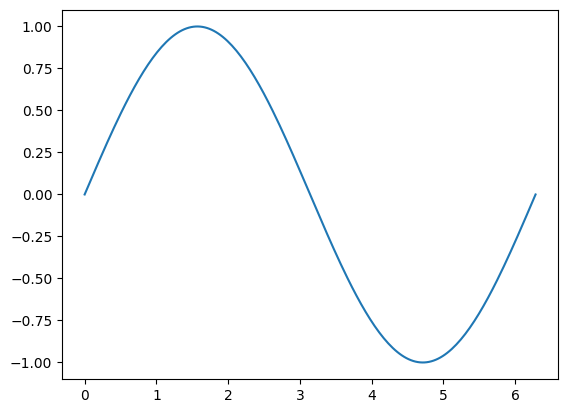

In [ ]:
x = torch.linspace(0,2*pi,200).unsqueeze(1)
label = torch.sin(x)
matplotlib.pyplot.plot(x,label)

###Tasks

1. Create a small MLP, `Sin()`, that takes one input, has a single hidden layer with 16 neurons and ReLU activation then an output layer with one output and no activation. This should require only small adaptation from the MLP used in exercise 1.
2. Decide on what loss function to use. The task here is regression not classification (you are predicting a continuous value). So don't use binary cross entropy loss.
3. Train your model. The training loop will be similar to exercise 1: pass the inputs `x` through your model, get predicted outputs, compare to `label` with your loss function and take a gradient descent step. Keep an eye on the loss value during training. If it's not reducing fast enough, increase learning rate (or try switching to the Adam optimiser). If it's diverging and going crazy, reduce the learning rate.
4. Once training has converged, plot the output of your network and compare it to the ground truth sinusoid. How well does it approximate the function? Can you see how ReLU is using straight line segments to approximate a curved function?
5. Repeat the above but make your network smaller (e.g. reduce the hidden neurons to 8). How good is the approximation now?


###Solutions

1.

In [ ]:
class Sin(nn.Module):
  def __init__(self):
    super(Sin, self).__init__()

    self.mlp = nn.Sequential(
                  nn.Linear(1,99),
                  nn.ReLU(),
                  nn.Linear(99,1)
    )
  def forward(self, x):
    x = x/torch.pi-1
    x = self.mlp(x)
    return x

2. and 3.

In [ ]:
model = Sin()
optim = torch.optim.SGD(model.parameters(), lr=0.01)

for epoch in range(5000):
  y = model(x)
  loss = torch.mean((y-label)**2)
  optim.zero_grad()
  loss.backward()
  optim.step()
  if not epoch % 200:
    print('[{:d}] Loss: {:.4f}'.format(epoch,loss.item()))

[0] Loss: 0.5686
[200] Loss: 0.1533
[400] Loss: 0.1253
[600] Loss: 0.1003
[800] Loss: 0.0783
[1000] Loss: 0.0597
[1200] Loss: 0.0445
[1400] Loss: 0.0327
[1600] Loss: 0.0240
[1800] Loss: 0.0177
[2000] Loss: 0.0133
[2200] Loss: 0.0103
[2400] Loss: 0.0082
[2600] Loss: 0.0068
[2800] Loss: 0.0058
[3000] Loss: 0.0051
[3200] Loss: 0.0046
[3400] Loss: 0.0042
[3600] Loss: 0.0038
[3800] Loss: 0.0036
[4000] Loss: 0.0033
[4200] Loss: 0.0031
[4400] Loss: 0.0029
[4600] Loss: 0.0027
[4800] Loss: 0.0025


4.

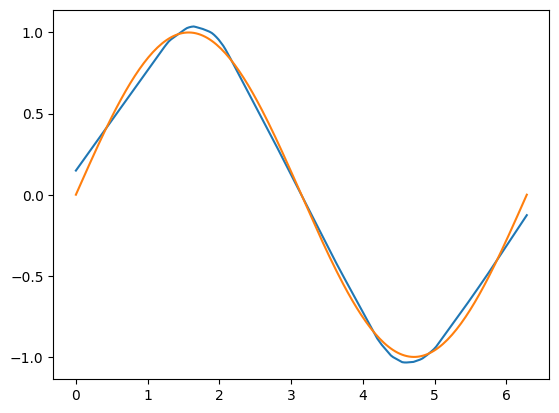

In [ ]:
y = model(x).detach().numpy()
matplotlib.pyplot.plot(x.numpy(),y)
matplotlib.pyplot.plot(x.numpy(),label)

## 🔎 Review: how a ReLU network builds a function, one line segment at a time

A single neuron with one input computes $z = wx + b$: a straight line with slope $w$ that crosses zero at $x = -b/w$. ReLU clamps it at zero, so the neuron's output is zero on one side of $x=-b/w$ (the **kink**) and the straight line on the other. If $w>0$ it is active to the right of the kink, if $w<0$ to the left.

Here's a minimal network with one input, two hidden neurons and one output, with weights chosen by hand:
$$y = v_1\,\mathrm{ReLU}(w_1x+b_1) + v_2\,\mathrm{ReLU}(w_2x+b_2) + c$$

In [ ]:
import matplotlib.pyplot as plt

w1, b1 = 1.0, -1.0     # neuron 1: kink at x = -b1/w1 = 1, active to the right
w2, b2 = 1.0, -3.0     # neuron 2: kink at x = 3, active to the right
v1, v2, c = 1.0, -2.0, 0.0

xs = torch.linspace(-1, 5, 601)
h1 = torch.relu(w1 * xs + b1)
h2 = torch.relu(w2 * xs + b2)
y = v1 * h1 + v2 * h2 + c

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(xs, h1, label='h1'); axes[0].plot(xs, h2, label='h2')
axes[0].set_title('Hidden neuron outputs'); axes[0].legend()
axes[1].plot(xs, v1 * h1, label='v1 * h1'); axes[1].plot(xs, v2 * h2, label='v2 * h2')
axes[1].set_title('Weighted by the output layer'); axes[1].legend()
axes[2].plot(xs, y, 'k')
axes[2].set_title('Output y')
for ax in axes:
    ax.axvline(-b1 / w1, color='grey', ls=':'); ax.axvline(-b2 / w2, color='grey', ls=':')
for (lo, hi, colour, slope) in [(-1, 1, 'whitesmoke', 0), (1, 3, 'lavender', v1 * w1), (3, 5, 'mistyrose', v1 * w1 + v2 * w2)]:
    axes[2].axvspan(lo, hi, color=colour, zorder=0)
    axes[2].text((lo + hi) / 2, 1.8, 'slope {:g}'.format(slope), ha='center')
plt.show()

Read the output region by region. For $x<1$ neither neuron is active: slope 0. For $1<x<3$ only neuron 1 is active: slope $v_1w_1 = 1$. For $x>3$ both are active: slope $v_1w_1 + v_2w_2 = 1-2 = -1$.

**When neuron $k$ switches on, the slope of the output changes by $v_k w_k$.** So each neuron adds exactly one bend, and $K$ neurons give at most $K$ bends, i.e. $K+1$ straight pieces.

*Try:* change the weights. Can you make a "bump" that goes up and comes back down to zero? (You'll need a third neuron.) What happens if $w_2 < 0$?

Now let's look at a trained network. This function finds every hidden neuron's kink and checks whether it lies inside the data.

In [ ]:
def kink_report(model, x_in):
    # model: nn.Sequential(Linear(1,H), ReLU(), Linear(H,1)); x_in: the inputs exactly as fed to the model
    w = model[0].weight.detach()[:, 0]
    b = model[0].bias.detach()
    pre = x_in @ model[0].weight.detach().T + b          # pre-activations, shape (N, H)
    dead = (pre <= 0).all(dim=0)                         # off for every training input
    kinks = -b / w
    inside = (~dead) & (kinks > x_in.min()) & (kinks < x_in.max())
    return dead, kinks, inside

def train_sin(hidden, rescale, lr, seed, epochs=5000, adam=False):
    # Train a one-hidden-layer ReLU MLP on the sinusoid. rescale=True maps x from 0..2pi to -1..1.
    x_train = torch.linspace(0, 2 * pi, 200).unsqueeze(1)
    y_train = torch.sin(x_train)
    x_in = x_train / pi - 1 if rescale else x_train
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    dead_at_init = kink_report(model, x_in)[0].sum().item()
    optimiser = (torch.optim.Adam if adam else torch.optim.SGD)(model.parameters(), lr=lr)
    for epoch in range(epochs):
        loss = torch.mean((model(x_in) - y_train) ** 2)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    return model, x_in, loss.item(), dead_at_init

model16, x_in, loss, _ = train_sin(16, rescale=True, lr=0.1, seed=3)
dead, kinks, inside = kink_report(model16, x_in)
x_plot = (x_in + 1) * pi                                  # back to original units for plotting
plt.figure(figsize=(9, 3.5))
plt.plot(x_plot, torch.sin(x_plot), '--', color='lightgrey', label='sin(x)')
plt.plot(x_plot, model16(x_in).detach(), label='16-neuron MLP')
for k in torch.where(inside)[0]:
    plt.axvline((kinks[k] + 1) * pi, color='tab:orange', lw=1)
plt.legend(); plt.show()
print('{} kinks inside the data, {} dead neurons, {} neurons with no kink in the data range'.format(
    inside.sum().item(), dead.sum().item(), 16 - inside.sum().item() - dead.sum().item()))

Each orange line is one neuron switching on or off. Notice where the network has put them: where the sinusoid bends most.

## 🔎 Review: dead neurons, and why we standardise inputs

A neuron that is **off for every training input** gets zero gradient for its weight and bias (ReLU's gradient is zero on the "off" side), so gradient descent never changes it. It is **dead**.

With inputs from $0$ to $2\pi$ (all positive), a neuron with $w<0$ **and** $b<0$ is off for every input. Note that a negative weight alone isn't enough: with $w<0$ and $b>0$ the neuron is active for small $x$ and can learn.

PyTorch initialises $w$ and $b$ uniformly in $(-1, 1)$ for a layer with one input. What fraction of neurons start dead?

In [ ]:
w = torch.rand(1_000_000) * 2 - 1
b = torch.rand(1_000_000) * 2 - 1
dead_raw = ((b < 0) & (b + 2 * pi * w < 0)).float().mean()   # off for all x in [0, 2pi]
dead_rescaled = (b < -w.abs()).float().mean()                 # off for all x in [-1, 1]
print('Dead at initialisation with inputs 0..2pi: {:.1f}%'.format(100 * dead_raw))
print('Dead at initialisation with inputs -1..1:  {:.1f}%'.format(100 * dead_rescaled))

About a quarter either way: rescaling the inputs does **not** stop neurons starting dead. That part is a lottery, which is one reason the random seed matters so much with only 16 neurons.

So what does rescaling change? Let's train 16-neuron networks with both input ranges for several seeds and count dead neurons before and after training.

In [ ]:
for rescale in [False, True]:
    print('Inputs rescaled to -1..1' if rescale else 'Inputs 0..2pi')
    for seed in range(5):
        model, x_in, loss, dead0 = train_sin(16, rescale, lr=0.1, seed=seed)
        dead1 = kink_report(model, x_in)[0].sum().item()
        print('   seed {}: dead at init {:2d}, after training {:2d}, final loss {:.4f}'.format(seed, dead0, dead1, loss))

With the raw inputs, many more neurons die **during** training, and the loss is usually much worse. Let's look at one run in detail: each row below is a hidden neuron, and the blue bar shows the inputs where it is active.

In [ ]:
def activity_plot(ax, model, x_in, rescale, title):
    pre = (x_in @ model[0].weight.detach().T + model[0].bias.detach())
    x_orig = ((x_in + 1) * pi if rescale else x_in)[:, 0]
    for row in range(pre.shape[1]):
        active = (pre[:, row] > 0).numpy()
        ax.fill_between(x_orig, row - 0.4, row + 0.4, where=active, color='tab:blue', step='mid')
    n_dead = (pre <= 0).all(dim=0).sum().item()
    ax.set_title('{} ({} dead)'.format(title, n_dead)); ax.set_yticks([])
    ax.set_xlim(0, 2 * pi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rescale in zip(axes, [False, True]):
    model, x_in, loss, _ = train_sin(16, rescale, lr=0.1, seed=3)
    activity_plot(ax, model, x_in, rescale, ('-1..1' if rescale else '0..2pi') + ' after training')
    ax.set_xlabel('x (original units)')
plt.show()

With inputs $0..2\pi$, after training no neuron is active above about $x=4$, so the output **must** be a flat line there. That's the flat tail many of you saw.

Why does this happen?

* **The kinks start in the wrong place.** Each kink starts at $-b/w$, which is mostly between $-1$ and $1$. That's spread across the data if the inputs are in $-1..1$, but bunched up near $x=0$ if they run to $2\pi$.
* **Big inputs give big kicks.** The gradient for a first-layer weight is proportional to its input. With $x$ up to 6.3 and a large error at the start, the first few steps are big. They push neurons that started with $w>0$ into the region where they're off for every input, and then they can never come back. (Try recording the dead count after 50 epochs: most of the deaths have already happened.)
* **Conditioning.** When every input is positive, changing $w$ and changing $b$ have very similar effects on the output, so the loss surface is a long thin valley that gradient descent zig-zags along. Centring the inputs makes $w$ and $b$ much more independent.

**The fix: standardise the inputs.** Subtract the mean and divide by the standard deviation of each feature, using statistics from the **training** set, and apply the same transform to the test set:

```python
mean, std = X_train.mean(dim=0), X_train.std(dim=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
```

**Isn't this feature engineering?** No. Feature engineering decides *what information* the model gets. Standardisation is a fixed, invertible change of units, and the first linear layer can undo it exactly: $W\frac{x-\mu}{\sigma} + b = \frac{W}{\sigma}x + (b - \frac{W\mu}{\sigma})$. The set of functions the network can represent is unchanged. Only the starting point and the shape of the loss surface change. Batchnorm and layernorm (this week's videos) are this same idea applied inside the network, at every layer.

*Try:* replace `nn.ReLU()` with `nn.LeakyReLU(0.1)` in `train_sin`. A leaky ReLU has a small slope instead of zero on the "off" side. What happens to the number of dead neurons and the loss with raw inputs?

## 🔎 Review: why does a wider network need a smaller learning rate?

Several people tried 1,000 hidden neurons and found training became unstable unless they lowered the learning rate. The output layer computes $y = \sum_k v_k h_k + c$. The gradient for each output weight is (error) $\times\, h_k$, so every one of the $K$ output weights gets nudged to fix the **same** error. All those nudges push the output the same way, so one step changes the output by roughly $\mathrm{lr}\times\mathrm{error}\times\sum_k h_k^2$, which grows in proportion to $K$.

We can measure this. The curvature of the loss with respect to the output layer is the largest eigenvalue of its Hessian, and plain gradient descent is only stable if the learning rate is below 2 / curvature.

In [ ]:
x_in = torch.linspace(0, 2 * pi, 200).unsqueeze(1) / pi - 1
for hidden in [10, 100, 1000]:
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    H = torch.relu(model[0](x_in)).detach()
    H = torch.cat([H, torch.ones(200, 1)], dim=1)          # include the output bias
    curvature = torch.linalg.eigvalsh(2 * H.T @ H / 200).max().item()   # Hessian of the MSE w.r.t. the output layer
    print('{:5d} neurons: curvature {:7.1f}  ->  largest stable learning rate about {:.4f}'.format(hidden, curvature, 2 / curvature))

10× the neurons, 10× the curvature, 10× smaller learning rate. (This is at initialisation; it changes during training, but the scaling with width is the point.) A big overshoot can also knock the hidden neurons dead, which leaves the output constant. A loss stuck at 0.4975 is exactly what you get by predicting the mean of $\sin(x)$.

**So how do we compare widths fairly?** Not at a single learning rate. Give each model its own best learning rate: sweep on a log scale, train each until the loss stops improving, then compare best against best. This cell runs a small sweep (about a minute).

In [ ]:
lrs = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
for use_adam in [False, True]:
    print('Adam' if use_adam else 'SGD')
    for hidden in [10, 100, 1000]:
        losses = [train_sin(hidden, True, lr, seed=0, epochs=3000, adam=use_adam)[2] for lr in lrs]
        print('   {:5d} neurons: '.format(hidden) + '  '.join('lr {}: {:.1e}'.format(lr, l) for lr, l in zip(lrs, losses)))

Things to notice:

* With SGD, each width has its own range of good learning rates, and the widest network breaks at a smaller learning rate. Lowering the learning rate in proportion to 1/width isn't a handicap: it keeps the size of each step **in the output** the same.
* Adam scales each parameter's step by the size of its own recent gradients, so it is much less sensitive to width. (Scaling the output layer by $1/\sqrt{K}$ is another fix, and is the idea behind "μP", which is used to tune learning rates on small models and transfer them to huge ones.)
* Best against best, 100 and 1,000 neurons both fit this noise-free sinusoid almost perfectly. To see a real benefit from extra width you'd need a harder function, or noisy data and a look at the fit between the training points (see the double descent notebook).

##Classifying the spiral dataset

The spiral dataset is a good example of a non-trivial binary classification problem. There are two input features for each data sample: the $x$ and $y$ coordinates of a point. The points belong to one of two classes, depending on which of the two interlocking spirals they lie on. The task is to create a small MLP that takes 2D input

###Generate the spiral dataset

The two classes are points lying on two spirals, rotated by 180 degrees and with some random noise added.

In [ ]:
N = 400
training_size = 600
theta = np.sqrt(np.random.rand(N))*2*pi

r_a = 2*theta + pi
data_a = np.array([np.cos(theta)*r_a, np.sin(theta)*r_a]).T
x_a = data_a + np.random.randn(N,2)

r_b = -2*theta - pi
data_b = np.array([np.cos(theta)*r_b, np.sin(theta)*r_b]).T
x_b = data_b + np.random.randn(N,2)

res_a = np.append(x_a, np.zeros((N,1)), axis=1)
res_b = np.append(x_b, np.ones((N,1)), axis=1)

res = np.append(res_a, res_b, axis=0)
np.random.shuffle(res)

X_train_tensor = torch.from_numpy(np.float32(res[:training_size,0:2]))
Y_train_tensor = torch.from_numpy(np.float32(res[:training_size,2])).unsqueeze(1)
X_test_tensor = torch.from_numpy(np.float32(res[training_size:,0:2]))
Y_test_tensor = torch.from_numpy(np.float32(res[training_size:,2])).unsqueeze(1)

Visualise the dataset by plotting the points in the training set and colouring according to the class.

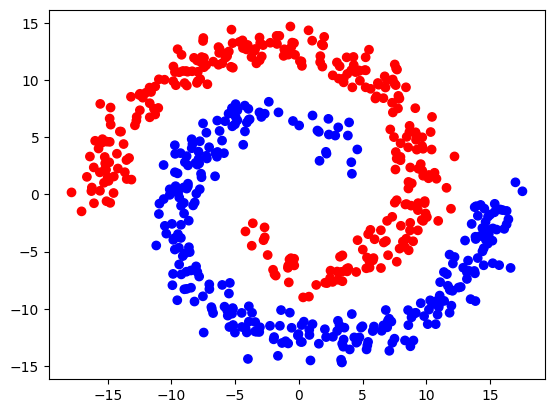

In [ ]:
colors = np.where(Y_train_tensor.squeeze(1).numpy() == 0, 'blue', 'red')
matplotlib.pyplot.scatter(X_train_tensor[:,0].numpy(),X_train_tensor[:,1].numpy(),c=colors)
matplotlib.pyplot.show()

As you can see, it would not be possible linearly separate these two classes (you can't draw a straight line that divides the points into the two classes). However, we will see that a very small ReLU MLP can do this perfectly.

###Tasks

1. Instantiate a small classification MLP with 2 inputs, one hidden layer with 16 neurons and sigmoid activation on the output. You can reuse the `MLP()` class from earlier for this.
2. Train the MLP to classify the spiral points into two classes.
3. Evaluate by printing classification performance on training and test sets. Plot the spiral points for the test set as above, but colour them according to the class predicted by your MLP rather than the ground truth labels.
4. Let's visualise what the MLP has actually learnt. For any point in 2D space, the MLP assigns a probability. We can visualise this as an image. Use `torch.meshgrid` to create a grid of points over the range -15..15 in $x$ and $y$. Pass all those points through your model to get probabilities. Display the probabilities as an image using matplotlib's `imshow`. You should be able to see the *decision boundary* i.e. the point where the probability is 0.5 and it is separating the two classes. Can you see the influence of ReLU here?
5. As an extra challenge, try to draw the decision boundary over the top of the image as a contour plot. Hint: `skimage.measure.find_contours` will be helpful here.


###Solutions

1. and 2.

In [ ]:
epochs=5000
# Instantiate MLP with 2 channel input and 16 hidden layers
model = MLP(2,16)
# Instantiate loss function (binary cross entropy loss - sigmoid applied inside model)
criterion = torch.nn.BCELoss()
# Setup optimiser
optim = torch.optim.SGD(model.parameters(), lr=0.1)

# Main training loop
for epoch in range(epochs):
    # Pass training data through model
    y_predict = model(X_train_tensor)
    # Compute BCE loss
    loss = criterion(y_predict,Y_train_tensor)
    # Backward pass and gradient step
    optim.zero_grad()
    loss.backward()
    optim.step()
    if not epoch % 200:
        # Print out the loss every 10 iterations
        print('epoch {}, loss {}'.format(epoch, loss.item()))

epoch 0, loss 0.7292764186859131
epoch 200, loss 0.4450713098049164
epoch 400, loss 0.42284682393074036
epoch 600, loss 0.37661421298980713
epoch 800, loss 0.3226868510246277
epoch 1000, loss 0.22998446226119995
epoch 1200, loss 0.08882203698158264
epoch 1400, loss 0.0627080425620079
epoch 1600, loss 0.05009084567427635
epoch 1800, loss 0.0416187047958374
epoch 2000, loss 0.03540952503681183
epoch 2200, loss 0.03069000318646431
epoch 2400, loss 0.02703065238893032
epoch 2600, loss 0.02403080463409424
epoch 2800, loss 0.02169223688542843
epoch 3000, loss 0.019777437672019005
epoch 3200, loss 0.018166465684771538
epoch 3400, loss 0.016782034188508987
epoch 3600, loss 0.015589088201522827
epoch 3800, loss 0.014548584818840027
epoch 4000, loss 0.013622555881738663
epoch 4200, loss 0.01280565932393074
epoch 4400, loss 0.012077941559255123
epoch 4600, loss 0.01142225693911314
epoch 4800, loss 0.010798485949635506


3.

Percent training set correctly classified: 100.00%
Percent test set correctly classified: 99.50%


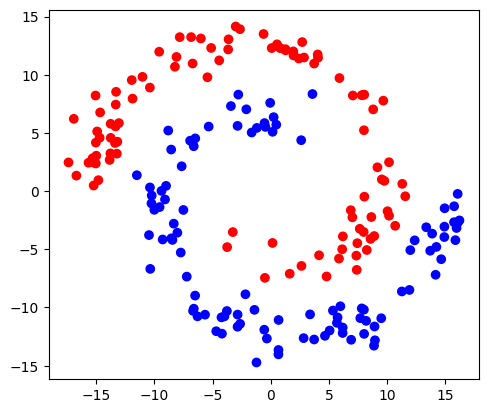

In [ ]:
y_predict = model(X_train_tensor)
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_train_tensor).float().sum()
print("Percent training set correctly classified: {:.2f}%".format(100*correct/training_size))

y_predict = model(X_test_tensor)
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_test_tensor).float().sum()
print("Percent test set correctly classified: {:.2f}%".format(100*correct/X_test_tensor.shape[0]))

colors = np.where(y_predict.squeeze(1).detach().numpy() < 0.5, 'blue', 'red')
matplotlib.pyplot.scatter(X_test_tensor[:,0].numpy(),X_test_tensor[:,1].numpy(),c=colors)
ax = matplotlib.pyplot.gca()
ax.set_aspect('equal', adjustable='box')
matplotlib.pyplot.show()

4. and 5.

[]

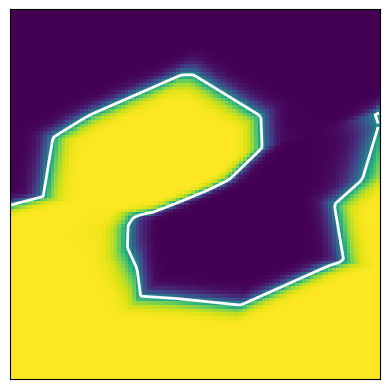

In [ ]:
from skimage import measure

# Choose a resolution for the image - I will use 100x100 pixels
res = 100
# Create a 100x100 grid for x and y going from -15 to 15
xs = torch.linspace(15, -15, steps=res)
ys = torch.linspace(-15, 15, steps=res)
X, Y = torch.meshgrid(xs, ys, indexing='xy')
# X and Y have size 100x100. We need to concatenate to create 2D channel input for the network.
# However, this would end up with something sized 100x100x2 whereas the network will only accept
# batch x 2. So, we need to flatten along the first two dimensions. This can be done with either
# reshape or flatten.
x=torch.cat((X.reshape(res**2,1),Y.reshape(res**2,1)),dim=1)
# Or equivalently:
# x=torch.cat((X.flatten().unsqueeze(1),Y.flatten().unsqueeze(1)),dim=1)

# Pass the grid of points through the trained model, then reshape back to 100x100
# The detach and numpy calls are needed to prepare the output to be passed to matplotlib.
p = model(x).reshape(res,res).detach().numpy()

# We can find the location of the decision boundary (places were p=0.5) using find_contours
contours = measure.find_contours(p, 0.5)

# Display the image
fig, ax = matplotlib.pyplot.subplots()
ax.imshow(p)

# Overlay the contours
for contour in contours:
    ax.plot(contour[:, 1], contour[:, 0], linewidth=2, c='white')

ax.set_xticks([])
ax.set_yticks([])

## 🔎 Review: why stacking linear layers collapses to one layer

The maths: $W_2(W_1x + b_1) + b_2 = (W_2W_1)x + (W_2b_1 + b_2)$, which is a single linear layer. Here's the same thing as a picture. A linear layer can only stretch, rotate, shear and shift space. Straight lines stay straight, and parallel lines stay parallel. Chain two together and you get exactly what the single combined layer gives. ReLU in between **folds** space, which no linear layer can do.

In [ ]:
t = torch.linspace(-1, 1, 101)
ticks = torch.linspace(-1, 1, 9)
W1 = torch.tensor([[1.1, 0.9], [-0.6, 1.0]]); b1 = torch.tensor([0.7, 0.45])
W2 = torch.tensor([[0.8, -0.7], [0.6, 0.9]]); b2 = torch.tensor([0.0, 0.1])
layer1 = lambda P: P @ W1.T + b1
layer2 = lambda P: P @ W2.T + b2

def draw_grid(ax, f, title):
    for v in ticks:
        horizontal = f(torch.stack([t, torch.full_like(t, v)], 1))
        vertical = f(torch.stack([torch.full_like(t, v), t], 1))
        ax.plot(horizontal[:, 0], horizontal[:, 1], color='tab:blue', lw=1)
        ax.plot(vertical[:, 0], vertical[:, 1], color='tab:orange', lw=1)
    ax.axhline(0, color='lightgrey', zorder=0); ax.axvline(0, color='lightgrey', zorder=0)
    ax.set_title(title); ax.set_aspect('equal'); ax.set_xlim(-1.5, 3.2); ax.set_ylim(-1.5, 3.2)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
draw_grid(axes[0, 0], lambda P: P, 'input')
draw_grid(axes[0, 1], layer1, 'linear layer 1')
draw_grid(axes[0, 2], lambda P: layer2(layer1(P)), 'linear layer 2')
draw_grid(axes[0, 3], lambda P: P @ (W2 @ W1).T + (W2 @ b1 + b2), 'ONE combined layer')
draw_grid(axes[1, 0], lambda P: P, 'input')
draw_grid(axes[1, 1], layer1, 'linear layer 1')
draw_grid(axes[1, 2], lambda P: torch.relu(layer1(P)), 'ReLU')
draw_grid(axes[1, 3], lambda P: layer2(torch.relu(layer1(P))), 'linear layer 2')
plt.show()

Top row: two linear layers give an identical picture to one combined layer. Bottom row: ReLU sets negative coordinates to zero, folding part of the grid flat onto the axes, and the second layer can't undo the fold.

Now on the spiral data from exercise 3: the same architecture with and without ReLU. (We divide the inputs by 10 so they are roughly in $-1..1$, for the reasons in the exercise 2 review.)

In [ ]:
def train_spiral(activation, epochs=3000):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(2, 32), activation(), nn.Linear(32, 32), activation(),
                        nn.Linear(32, 32), activation(), nn.Linear(32, 1))
    optimiser = torch.optim.Adam(net.parameters(), lr=0.01)
    criterion = nn.BCEWithLogitsLoss()
    for epoch in range(epochs):
        loss = criterion(net(X_train_tensor / 10), Y_train_tensor)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    return net

grid = torch.linspace(-15, 15, 150)
GX, GY = torch.meshgrid(grid, grid, indexing='xy')
points = torch.stack([GX.flatten(), GY.flatten()], 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, activation, name in zip(axes, [nn.Identity, nn.ReLU], ['no activation', 'ReLU']):
    net = train_spiral(activation)
    accuracy = ((net(X_train_tensor / 10) > 0).float() == Y_train_tensor).float().mean().item()
    p = torch.sigmoid(net(points / 10)).reshape(150, 150).detach()
    ax.imshow(p, extent=(-15, 15, -15, 15), origin='lower', cmap='RdBu_r', alpha=0.4)
    ax.contour(grid, grid, p, levels=[0.5], colors='k')
    colours = np.where(Y_train_tensor.squeeze(1).numpy() == 0, 'blue', 'red')
    ax.scatter(X_train_tensor[:, 0], X_train_tensor[:, 1], c=colours, s=5)
    ax.set_title('3 hidden layers, {}: training accuracy {:.0f}%'.format(name, 100 * accuracy))
plt.show()

Without an activation function, three hidden layers of 32 units are still just logistic regression: the decision boundary has to be a straight line, however long you train. With ReLU, the same architecture wraps the boundary around the spiral.

## 🔎 Review: how many neurons and layers?

Like the learning rate, the number of hidden neurons and layers are hyperparameters: try several values and compare them on a **validation** set (never the test set). Here we hold out part of the exercise 3 training data as a validation set and try every combination of 1–4 hidden layers and 2–256 neurons per layer. This takes a couple of minutes; reduce `epochs` or the lists to speed it up.

In [ ]:
def make_mlp(width, depth):
    layers = [nn.Linear(2, width), nn.ReLU()]
    for _ in range(depth - 1):
        layers += [nn.Linear(width, width), nn.ReLU()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

# hold out the last 150 training points as a validation set (inputs scaled to roughly -1..1)
X_fit, Y_fit = X_train_tensor[:450] / 10, Y_train_tensor[:450]
X_val, Y_val = X_train_tensor[450:] / 10, Y_train_tensor[450:]

widths, depths = [2, 4, 8, 16, 64, 256], [1, 2, 3, 4]
val_acc = np.zeros((len(depths), len(widths)))
for i, depth in enumerate(depths):
    for j, width in enumerate(widths):
        accs = []
        for seed in range(2):
            torch.manual_seed(seed)
            net = make_mlp(width, depth)
            optimiser = torch.optim.Adam(net.parameters(), lr=0.01)
            for epoch in range(2000):
                loss = nn.functional.binary_cross_entropy_with_logits(net(X_fit), Y_fit)
                optimiser.zero_grad()
                loss.backward()
                optimiser.step()
            accs.append(100 * ((net(X_val) > 0).float() == Y_val).float().mean().item())
        val_acc[i, j] = np.mean(accs)

plt.figure(figsize=(7, 3.5))
plt.imshow(val_acc, cmap='Blues', origin='lower', aspect='auto', vmin=50, vmax=100)
for i in range(len(depths)):
    for j in range(len(widths)):
        plt.text(j, i, '{:.0f}'.format(val_acc[i, j]), ha='center', va='center',
                 color='white' if val_acc[i, j] > 85 else 'black')
plt.xticks(range(len(widths)), widths); plt.yticks(range(len(depths)), depths)
plt.xlabel('neurons per hidden layer'); plt.ylabel('hidden layers'); plt.title('Validation accuracy (%)')
plt.show()

A recipe:

1. **Big enough first.** If the training loss won't go down, the model is too small: no learning rate fixes underfitting.
2. **Search on a log scale**: 16, 64, 256, ... neurons; 1, 2, 3 hidden layers is usually plenty for an MLP on data like this. Retune the learning rate for each size and use a few seeds. With many hyperparameters at once, random combinations beat a grid.
3. **When in doubt, go bigger**, and control overfitting with regularisation and early stopping (week 5). Past the plateau, bigger rarely hurts much. On noisier or smaller datasets the validation accuracy would eventually drop for very large models, and the validation set is how you'd see it.

*Try:* repeat with fewer training points (e.g. the first 100) or more noise in the spiral. Does the best size change?